In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.
Fontconfig warning: ignoring C.UTF-8: not a valid language tag


In [2]:
np.random.seed(42)

## 0. Build dataframe
This code generates a 156-row dataframe with weekly Monday starts from 2023-01-02.

In [4]:
# 156 weeks = 3 years
n = 156

dates = pd.date_range(
    start="2023-01-02",
    periods=n,
    freq="W-MON"
)

df = pd.DataFrame({"date": dates})

In [5]:
df.head()

,date
0,2023-01-02
1,2023-01-09
2,2023-01-16
3,2023-01-23
4,2023-01-30


## 1. Generate marketing spend ($)
This code generates 4 columns:
* `tv_spend`, `search_spend`, `social_spend`, `display_spend` based off of lognormal distributions.
* These columns represent weekly marketing expenditure across each channel, respectively.

In [6]:
df["tv_spend"] = np.random.lognormal(
    mean=np.log(40000), sigma=0.25, size=n
)

df["search_spend"] = np.random.lognormal(
    mean=np.log(20000), sigma=0.20, size=n
)

df["social_spend"] = np.random.lognormal(
    mean=np.log(15000), sigma=0.30, size=n
)

df["display_spend"] = np.random.lognormal(
    mean=np.log(8000), sigma=0.25, size=n
)

## 2. Generate business controls
This code generates 4 columns:
* `price_index` - average product price
* `promotion` - promotional intensity
* `distribution` - % of stores carrying products
* `holiday` - boolean for Nov, Dec

In [7]:
df["price_index"] = np.random.normal(1.0, 0.025, n)

df["promotion"] = np.random.binomial(1, 0.25, n)

df["distribution"] = np.random.uniform(0.85, 0.98, n)

df["holiday"] = (
    df["date"].dt.month.isin([11, 12])
).astype(int)

## 3. Generate underlying adstock
What is adstock?

Adstock is the prolonged, lagged effect that an advertising campaign has on consumer behavior and sales after the ads stop running.

Here we set the true alpha (adstock decay rate) - TV has a decay rate of 0.65, social has decay rate of 0.45, and so on.

We see that the adstock for each week is a combination of the latest week's spend + the decayed adstock from the prior week - essentially, a recursive formula with $\alpha$ as the decay rate, i.e.

$$AdStock_t = Spend_t / 1000 + \alpha * AdStock_{t-1}$$

After we run the decay rate across all of the weekly spend per channel, we obtain cumulative adstock values for each channel under the columns:
* `tv_adstock_true`, `search_adstock_true`, `social_adstock_true`, `display_adstock_true`

### Notes: in the real world these values are estimated and not observable!
We compute them here in the simulation to use for comparison, but in the real world these values are not known.

In [8]:
true_alpha = {
    "tv": 0.65,
    "search": 0.25,
    "social": 0.45,
    "display": 0.35
}

for channel in true_alpha:

    spend = df[f"{channel}_spend"].values / 1000

    adstock = np.zeros(n)

    adstock[0] = spend[0]

    for t in range(1, n):
        adstock[t] = (
            spend[t] +
            true_alpha[channel] * adstock[t-1]
        )

    df[f"{channel}_adstock_true"] = adstock

## 4. Generate diminishing returns
What is happening in this cell?

EC50 stands for Effective Concentration 50%. It is the adstocked spend necessary to hit 50% of channel saturation. Lower EC50 values for a given channel mean that the channel will reach 50% saturation for lower adstocked spend. But saturation does not necessarily imply channel effectiveness, which is a separate variable.

Based off of the EC50 values, we compute the channel effect by multiplying it against a "saturation multiplier", which uses the adstocked spend column as well as the EC50 values.

### Again, note that in the real world these values are all unobservable!
We use it to generate our data and we will compare our model later against these true values.


In [9]:
ec50 = {
    "tv": 180,
    "search": 35,
    "social": 65,
    "display": 30
}

channel_effect = {
    "tv": 45000,
    "search": 35000,
    "social": 28000,
    "display": 16000
}

for channel in true_alpha:

    x = df[f"{channel}_adstock_true"]

    df[f"{channel}_contribution_true"] = (
        channel_effect[channel] *
        x / (x + ec50[channel])
    )

## 5. Generate baseline and business effects
Note the trend is just a linearly increasing sequence.

On the other components:
* Seasonality is a periodic sine wave every 52 weeks oscillating between 10000 and -10000.
* Price effect has a baseline of -250000 multiplied by a factor of price_index - 1:
    * If price index is less than 1, than the price effect is slightly positive.
    * Otherwise, the price effect is slightly negative.
* Distribution effect has a baseline of 150000:
    * If distribution is < 0.9, then distribution effect is slightly negative.
    * If distribution > 0.9, then distribution effect is slightly positive.
* Promotion has a flat effect of 12000 when a promotion is in place.
* holidays also have a flat effect of 8000 for Nov, Dec.

In [11]:
trend = np.arange(n) * 200

seasonality = (
    10000 * np.sin(2 * np.pi * np.arange(n) / 52)
)

promotion_effect = df["promotion"] * 12000

price_effect = -250000 * (
    df["price_index"] - 1
)

distribution_effect = 150000 * (
    df["distribution"] - 0.90
)

holiday_effect = df["holiday"] * 8000

Text(0.5, 1.0, 'Promotion effect')

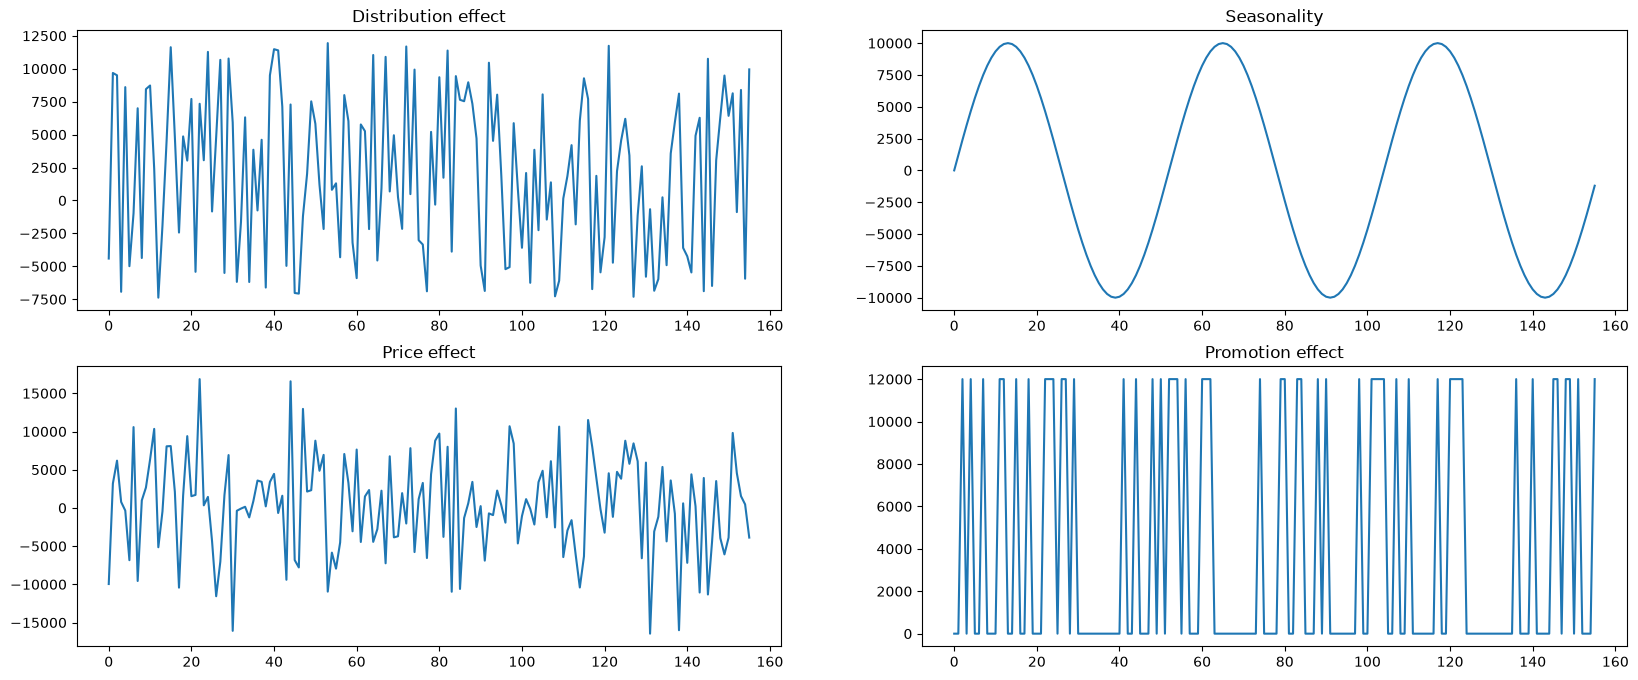

In [31]:
fig, ax = plt.subplots(2,2, figsize=(20, 8))

ax[0,0].plot(distribution_effect)
ax[0,0].set_title('Distribution effect')
ax[0,1].plot(seasonality)
ax[0,1].set_title('Seasonality')
ax[1,0].plot(price_effect)
ax[1,0].set_title('Price effect')
ax[1,1].plot(promotion_effect)
ax[1,1].set_title('Promotion effect')

## 6. Generate revenue
Lastly, we combine all the baseline, business effects + marketing effects into an overall revenue number (+ a noise variable).

In [33]:
marketing_effect = sum(
    df[f"{channel}_contribution_true"]
    for channel in true_alpha
)

noise = np.random.normal(0, 6000, n)

df["revenue"] = (
    150000
    + trend
    + seasonality
    + marketing_effect
    + promotion_effect
    + price_effect
    + distribution_effect
    + holiday_effect
    + noise
)

## 7. Save dataset

In [34]:
df.to_csv("freshbite_marketing_data.csv", index=False)

print(df.head())
print(df.shape)

        date      tv_spend  search_spend  social_spend  display_spend  \
0 2023-01-02  45288.719887  29046.185767  19214.690291    7006.345615   
1 2023-01-09  38640.980289  21988.044146  19146.177587    6927.416758   
2 2023-01-16  47030.747439  15759.944678  22191.156269    7468.383803   
3 2023-01-23  58535.705485  22806.440982  15094.815698    4499.477372   
4 2023-01-30  37725.683047  16457.740926  18405.252623    5477.472523   

   price_index  promotion  distribution  holiday  tv_adstock_true  \
0     1.039830          0      0.870619        0        45.288720   
1     0.987220          0      0.964513        0        68.078648   
2     0.975260          1      0.963340        0        91.281869   
3     0.996855          0      0.853802        0       117.868920   
4     1.001393          1      0.957356        0       114.340481   

   search_adstock_true  social_adstock_true  display_adstock_true  \
0            29.046186            19.214690              7.006346   
1       

In [35]:
df.head()

,date,tv_spend,search_spend,social_spend,display_spend,price_index,promotion,distribution,holiday,tv_adstock_true,search_adstock_true,social_adstock_true,display_adstock_true,tv_contribution_true,search_contribution_true,social_contribution_true,display_contribution_true,revenue
0,2023-01-02,45288.719887,29046.185767,19214.690291,7006.345615,1.039830,0,0.870619,0,45.288720,29.046186,19.214690,7.006346,9046.135980,15873.177921,6388.568625,3029.251551,177876.881607
1,2023-01-09,38640.980289,21988.044146,19146.177587,6927.416758,0.987220,0,0.964513,0,68.078648,29.249591,27.792788,9.379638,12349.064265,15933.730647,8386.406800,3810.959477,205943.203402
2,2023-01-16,47030.747439,15759.944678,22191.156269,7468.383803,0.975260,1,0.963340,0,91.281869,23.072342,34.697911,10.751257,15141.756851,13905.620973,9744.853204,4221.222233,235944.154056
3,2023-01-23,58535.705485,22806.440982,15094.815698,4499.477372,0.996855,0,0.853802,0,117.868920,28.574527,30.708876,8.262417,17806.830619,15731.276091,8983.999781,3455.052933,189844.571656
4,2023-01-30,37725.683047,16457.740926,18405.252623,5477.472523,1.001393,1,0.957356,0,114.340481,23.601373,32.224247,8.369319,17480.849499,14096.052765,9280.389794,3490.004574,230465.457106


# Explore the dataset

In [44]:
pd.set_option('display.max_colwidth', None)

In [46]:
### Descriptive statistics
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,156,2024-06-27 12:00:00,2023-01-02 00:00:00,2023-09-30 06:00:00,2024-06-27 12:00:00,2025-03-25 18:00:00,2025-12-22 00:00:00,NaN
tv_spend,156.0,40265.343031,20779.006582,33766.024018,39648.86165,44445.642907,74046.256239,9504.959342
search_spend,156.0,20762.175419,10459.166862,17542.803934,20467.061114,22974.254403,43218.929048,4405.094478
social_spend,156.0,15775.677881,7931.811801,12142.741682,15075.794335,18354.490724,28933.239244,4614.668049
display_spend,156.0,8204.435179,4312.554486,6605.940198,8010.496148,9240.656951,17273.296322,2169.458438
price_index,156.0,0.998658,0.932578,0.982098,0.997869,1.015611,1.06581,0.025733
promotion,156.0,0.326923,0.0,0.0,0.0,1.0,1.0,0.4706
distribution,156.0,0.913738,0.85083,0.876056,0.914381,0.948933,0.979626,0.039628
holiday,156.0,0.160256,0.0,0.0,0.0,0.0,1.0,0.368025
tv_adstock_true,156.0,113.734045,45.28872,105.498032,114.169529,121.163245,147.887547,13.132006


**What is the average weekly revenue?**

The average weekly revenue across the dataset is about 220K.

**Which channel has the highest average spend?**

TV has the highest weekly average spend.

**Which channel has the greatest variability in spend?**

TV also has the highest variability in spend, followed by social, search, and display.

**Are there any suspicious values?**

I don't see anything particularly suspicious, which makes sense, since this is a synthetic dataset.

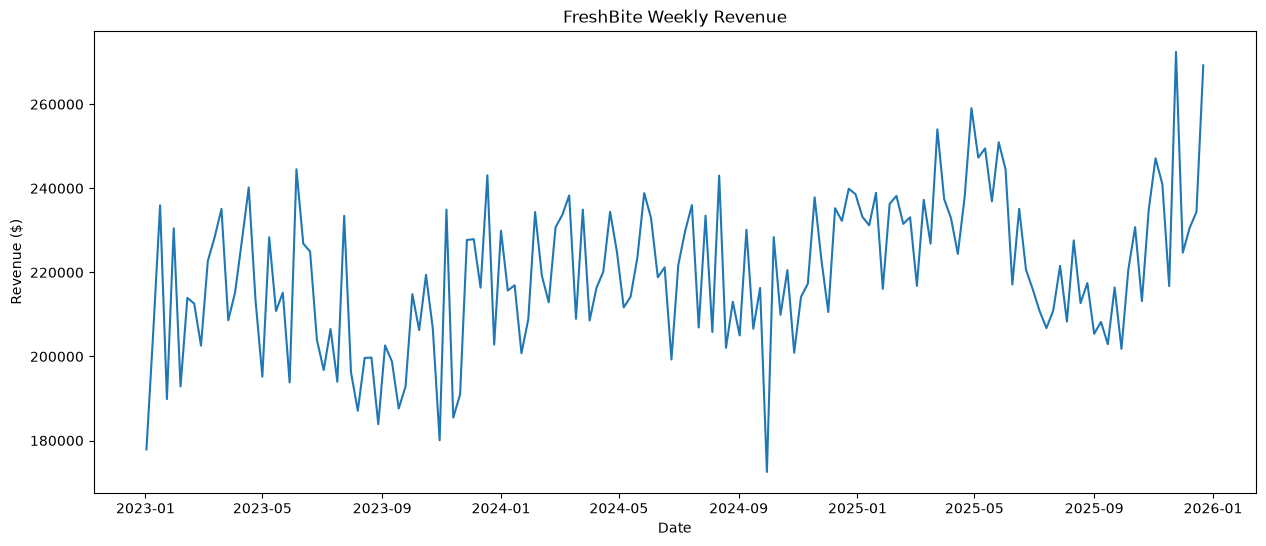

In [49]:
### Revenue over time
plt.figure(figsize=(15,6))
plt.plot(df["date"], df["revenue"])

plt.title("FreshBite Weekly Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue ($)")

plt.show()

**Long-term growth.**

Long-term, weekly revenue is trending positively. This is expected given the inputs into our synthetic dataset.

**Seasonal patterns.**

It's a big hard to see in the first half of the dataset but there is a seasonal dip in each year around Q3 that bottoms out around September.

**Unusual spikes or drops.**

There is one particularly bad drop around Sep-Oct 2024 in terms of revenue.

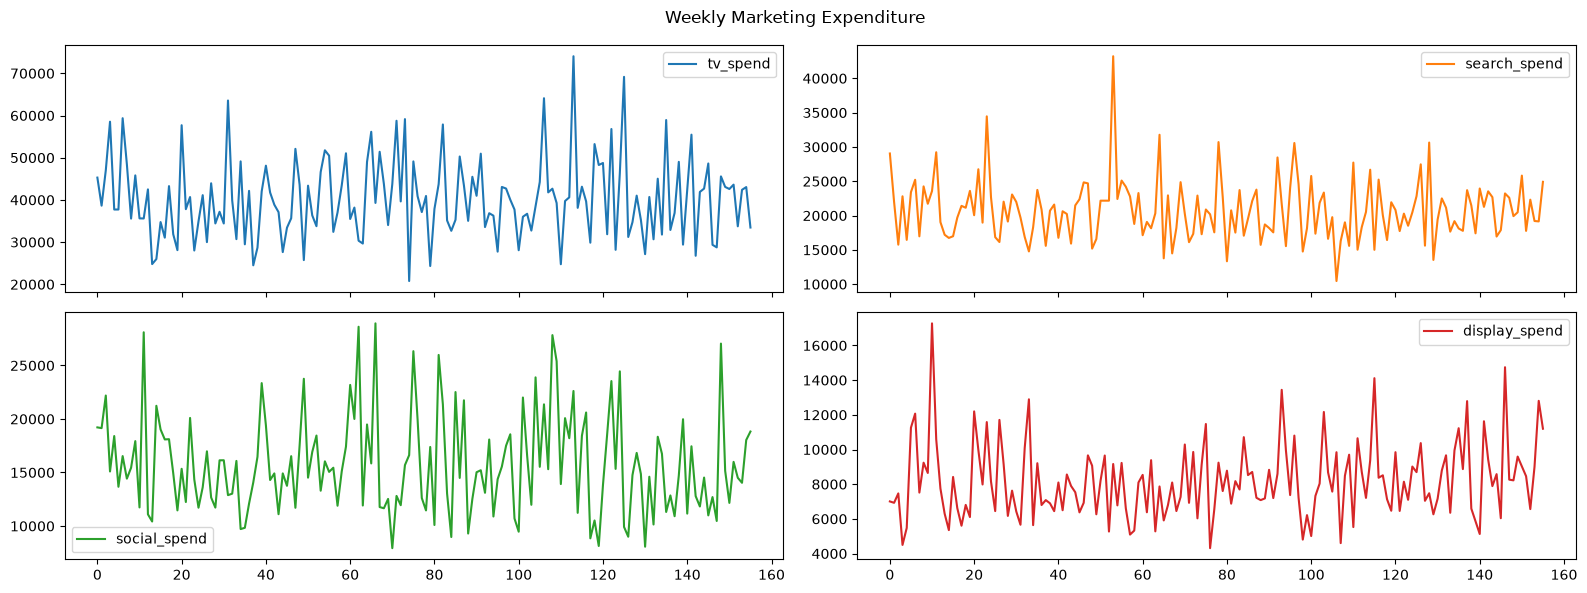

In [51]:
### Marketing expenditure
channels = ["tv_spend", "search_spend", "social_spend", "display_spend"]

df[channels].plot(figsize=(16, 6), subplots=True, layout=(2,2), title="Weekly Marketing Expenditure")
plt.tight_layout()
plt.show()

### Some notes on the marketing expenditure charts
* Overall, marketing expenditure per channel seems pretty consistent throughout the year. Noting that the y-axes are at different ranges, though.

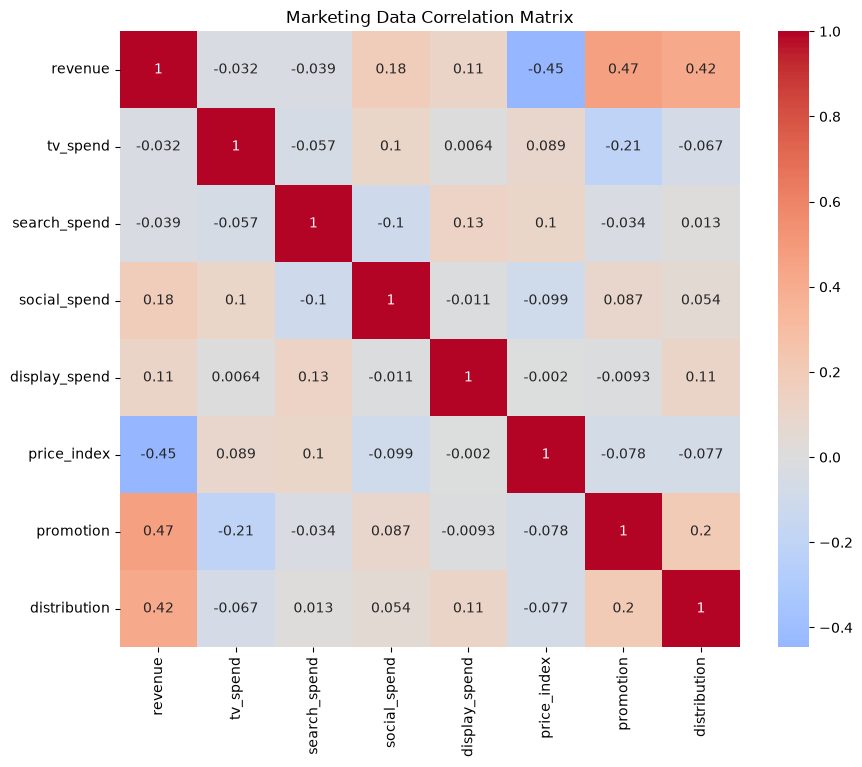

In [52]:
### Correlation analysis
variables = [
    "revenue",
    "tv_spend",
    "search_spend",
    "social_spend",
    "display_spend",
    "price_index",
    "promotion",
    "distribution"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[variables].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Marketing Data Correlation Matrix")

plt.show()

### Some comments on the correlation analysis:
* Revenue has strong negative correlation against price index, which makes sense.
* Revenue also has high correlation with promotion + distribution, which are also intuitive.
* Revenue has a slightly low (near zero) correlation with TV and search spend, but a higher correlation with social + display.

### A few diagnostic questions:

**1. Why might a high correlation between TV spend and revenue not mean TV advertising caused the increase in revenue?**

The main reason is that correlation doesn't establish a causal relationship. There could be a major holiday that drives both advertising spend as well as revenue, but we don't know if the increase in revenue is causal unless we run a counterfactual analysis.

**2. Why do we need variables such as price, promotions, and distribution in our MMM?**

We should include these because these are known factors that we are confident has an impact on revenue. Therefore, if we don't include them in our model, they are known confounders that could skew the estimated effect of marketing spend. In particular, not including them introduces **omitted variable bias** into the model.

**3. Why might weekly marketing spend be a better input than quarterly marketing spend?**

Capturing weekly marketing spend gives us more observations for our model to capture more variability between weeks and therefore be more flexible to understanding the impact of weekly spend on weekly revenue. I should note, if we think the quarterly aggregates provide some additional effect, we can add BOTH weekly + quarterly aggregates into the model - it doesn't need to just be a binary choice. 

However, we should also consider the granularity at which decisions are being made - if our marketing team optimizes budget weekly, then choosing weekly marketing spend is a more accurate alignment to how the business actually works.

Weekly marketing spend also allows us to more granularly and accurately model adstock and carryover effects as they decay weekly - if we tried to model adstock decay at a quarterly level, it would be much more coarse and likely not as true to reality.

Overall, the additional flexibility is the key benefit of modeling at the weekly level, though again, we can include a quarterly spend feature as well.

**4. Why is it useful that we know the true adstock parameters in our synthetic dataset?**

Knowing the true adstock parameters gives us a target against which we can benchmark our model. After we estimate our model, we can then understand how far off it is from the true parameters. One of the benefits of using a synthetic is that we know the answers (which is not true in real life) and have greater ability to then debug and figure out what exactly is going wrong in our model, or if the error is just due to generated noise in the observations.